In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [9]:
sales = pd.read_csv("python_project 1 csv.csv")
sales.head()

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Customer_Age,City,State,Region,Product_ID,Product_Name,Category,Unit_Price_NGN,Quantity,Discount,Payment_Method,Sales_Channel,Order_Status,Sales_NGN,Profit_NGN
0,ORD00001,22/05/2024,28/05/2024 19:00,CUST0280,Chidi Ojo,45.0,Akure,Ondo,South West,P001,Wireless Mouse,Electronics,8500,5,0,ussd,Phone Order,Returned,42500,14450
1,ORD00002,19 July 2025,24/07/2025,CUST0036,Bola Balogun,32.0,Bauchi,Bauchi,North East,P002,USB Keyboard,Electronics,12500,10,0.05,Cash,Phone Order,Delivered,118750,32953.12
2,ORD00003,01/10/2024 09:15,06 October 2024,CUST0162,Grace Balogun,49.0,Benin City,Edo,South South,P014,External Hard Drive,Electronics,68000,1,0,WALLET,Phone Order,Returned,68000,14960
3,ORD00004,27 April 2024,2024-05-04,CUST0175,Dami Eze,45.0,BAUCHI,Bauchi,North East,P014,External Hard Drive,Electronics,68000,10,0.1,NaN,In-store,Returned,612000,94860
4,ORD00005,28/03/2024,04/04/2024,CUST0273,Emeka Bello,60.0,Ibadan,Oyo,South West,P004,Phone Charger,Accessories,6500,6,0.2,Bank Transfer,PHONE ORDER,Delivered,31200,4680


In [ ]:
import pandas as pd
import numpy as np

# 1. Make a copy of the original dataset
sales = sales.copy()

# 2. Remove duplicate records
sales = sales.drop_duplicates()

# 3. Clean and standardise text columns
text_columns = [
"Customer_Name", "City", "State", "Region",
"Product_Name", "Category", "Payment_Method",
"Sales_Channel", "Order_Status"
]

for col in text_columns:
    sales[col] = (
sales[col]
.astype("string")
.str.strip()
.str.title()
)

# 4. Standardise category names
sales["Category"] = sales["Category"].replace({
"Electronic": "Electronics",
"Stationary": "Stationery",
"Furnitures": "Furniture",
"Life Style": "Lifestyle"
})

# 5. Standardise region names
sales["Region"] = sales["Region"].replace({
"Northeast": "North East",
"Northwest": "North West",
"Northcentral": "North Central",
"Southwest": "South West",
"Southeast": "South East",
"Southsouth": "South South"
})

# 6. Clean date columns
for col in ["Order_Date", "Ship_Date"]:
    sales[col] = pd.to_datetime(
sales[col],
errors="coerce",
dayfirst=True,
format="mixed"
)

# 7. Clean numeric columns
numeric_columns = [
"Customer_Age",
"Unit_Price_NGN",
"Quantity",
"Discount",
"Sales_NGN",
"Profit_NGN"
]

for col in numeric_columns:
    sales[col] = (
sales[col]
.astype("string")
.str.replace("₦", "", regex=False)
.str.replace(",", "", regex=False)
.str.replace("%", "", regex=False)
.str.strip()
)

sales[col] = pd.to_numeric(
sales[col],
errors="coerce"
)

# 8. Convert percentage discounts to decimals
sales["Discount"] = sales["Discount"].astype("float64")

sales.loc[
sales["Discount"] > 1,
"Discount"
] = sales.loc[
sales["Discount"] > 1,
"Discount"
] / 100

# 9. Remove invalid customer ages
sales['Customer_Age'] = pd.to_numeric(sales['Customer_Age'],errors='coerce')
sales.loc[
~sales["Customer_Age"].between(18, 100),
"Customer_Age"
] = np.nan

# 10. Remove invalid quantities
sales['Quantity'] = pd.to_numeric(sales['Quantity'],errors='coerce')
sales.loc[
sales["Quantity"] <= 0,
"Quantity"
] = np.nan

# 11. Remove invalid discounts
sales.loc[
~sales["Discount"].between(0, 1),
"Discount"
] = np.nan

# 12. Remove records without essential information
sales = sales.dropna(subset=[
"Order_ID",
"Order_Date",
"Category",
"Sales_NGN",
"Profit_NGN"
])

# 13. Create additional date columns
sales["Month"] = sales["Order_Date"].dt.month_name()
sales["Year"] = sales["Order_Date"].dt.year
sales["Month_Year"] = sales["Order_Date"].dt.to_period("M").astype(str)

# 14. Display cleaned dataset information
print("CLEANING COMPLETED SUCCESSFULLY")

print("\nDataset Information:")
sales.info()

print("\nMissing Values:")
print(sales.isnull().sum())

print("\nStandardised Categories:")
print(sales["Category"].value_counts())

print("\nStandardised Regions:")
print(sales["Region"].value_counts())

print("\nFinal Dataset Shape:")
print(sales.shape)

print("\nFirst Five Rows:")
print(sales.head())

CLEANING COMPLETED SUCCESSFULLY

Dataset Information:
<class 'pandas.DataFrame'>
Index: 1183 entries, 0 to 1199
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        1183 non-null   str           
 1   Order_Date      1183 non-null   datetime64[us]
 2   Ship_Date       991 non-null    datetime64[us]
 3   Customer_ID     1183 non-null   str           
 4   Customer_Name   1161 non-null   string        
 5   Customer_Age    1165 non-null   Float64       
 6   City            1174 non-null   string        
 7   State           1183 non-null   string        
 8   Region          1183 non-null   string        
 9   Product_ID      1183 non-null   str           
 10  Product_Name    1175 non-null   string        
 11  Category        1183 non-null   string        
 12  Unit_Price_NGN  1183 non-null   string        
 13  Quantity        1178 non-null   Int64         
 14  Discount        11

   Month_Year                                          Sales_NGN
0     2024-01  4896002565001824005760032000510001900005985086...
1     2024-02  2312001674078375228001224006120085003040007410...
2     2024-03  3120085000768001615042752052090000990036125484...
3     2024-04  6120003750021000337502890055802565003420028500...
4     2024-05  4250013600021600080750119700100000540002560046...
5     2024-06  5780049500198900167401920011250180007837524960...
6     2024-07  1215048601105010450378001650002223006480025650...
7     2024-08  1710765018000195001062517280021000780001800550...
8     2024-09  275000136800?240000.00255003375012500900012150...
9     2024-10  6800016200233755500042160475000125001306251224...
10    2024-11  1920020400013000825007125004512503672001250018...
11    2024-12  4050117805270960007200014400024000025000312000...
12    2025-01  2106002250011700025000780002160019200010540189...
13    2025-02  8500052253990064800390000128000450090003040009...
14    2025-03  8670017100

C:\Users\C.E\AppData\Local\Temp\ipykernel_952\4287028140.py:25: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


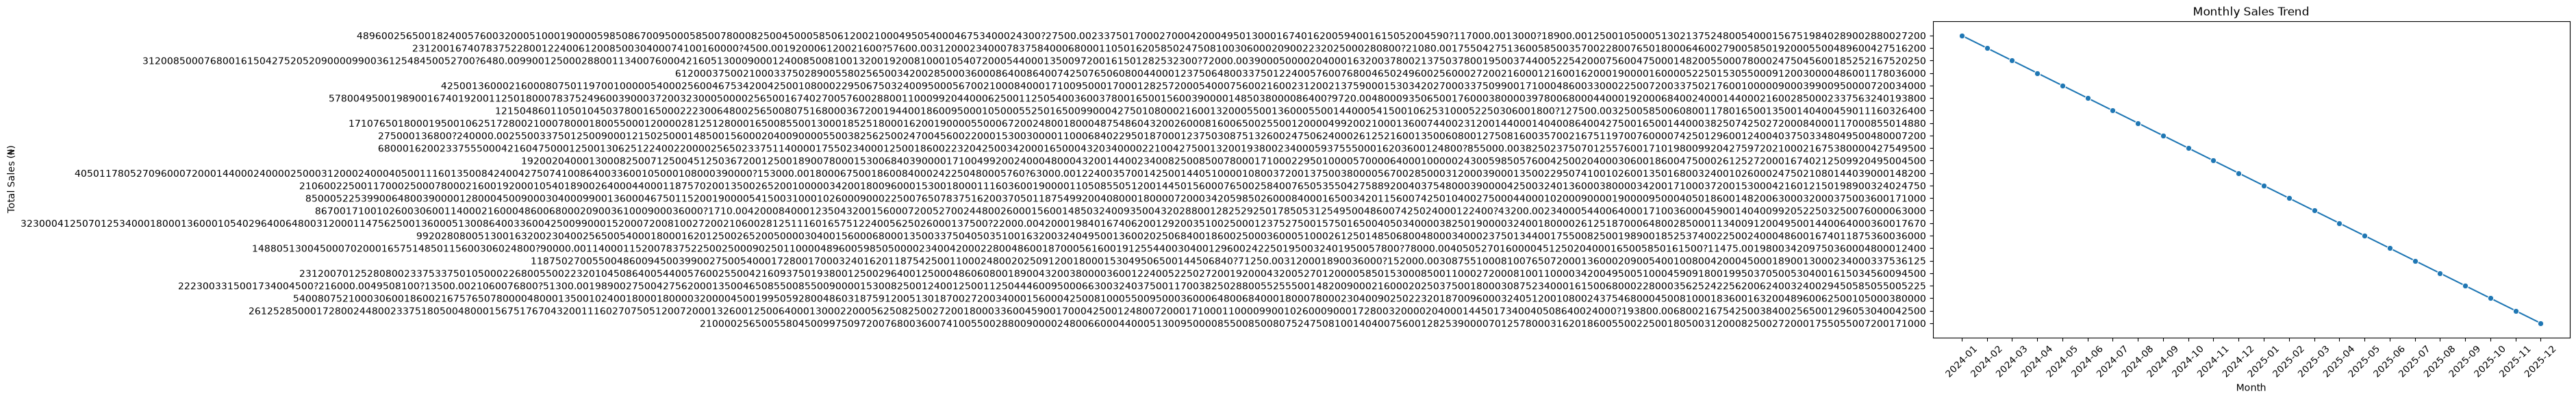

In [14]:
#How did sales chnage overtime
# Calculate monthly sales
monthly_sales = sales.groupby("Month_Year")["Sales_NGN"].sum().reset_index()

# Sort by month
monthly_sales = monthly_sales.sort_values("Month_Year")

# Display results
print(monthly_sales)

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
data=monthly_sales,
x="Month_Year",
y="Sales_NGN",
marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₦)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()